In [1]:
%matplotlib inline

In [2]:
import os
import numpy as np
import pandas as pd

In [3]:
max_legs = 5
max_trips = 30

In [4]:
tripchains_infolder = r'../generation/outputs/OPsplit'
tripchains_filename = 'tripchains_{}legs_over{}trips.csv'.format(max_legs, max_trips)
tripchains_infilepath = os.path.join(tripchains_infolder, tripchains_filename)

distances_infolder = r'./inputs'
distances_filename = 'distances_ModelZonesSystem.csv'
distances_infilepath = os.path.join(distances_infolder, distances_filename)

In [5]:
def read_tripchains(infilepath):
    df = pd.read_csv(infilepath)
    df.TimePeriod = df.TimePeriod.astype('category')
    df.TimePeriod.cat.reorder_categories(['OP1', 'AM', 'IP', 'PM', 'OP2'],
                                         ordered=True, inplace=True)
    return df

In [6]:
def read_distances(infilepath):
    df = pd.read_csv(infilepath, index_col=[0, 1], squeeze=True)
    return df

In [20]:
def prepare_dist_labes_from_bins(bins, concat_char='to'):
    labels = []
    for v, w in zip(bins[:-1], bins[1:]):
        labels.append('{}{}{}'.format(v, concat_char, w))
    labels[-1] = '{}+'.format(bins[-2])
    return labels

In [21]:
tcs = read_tripchains(tripchains_infilepath)
dists = read_distances(distances_infilepath)

In [22]:
tcs.head(2)

,TripChainID,OrigID,DestID,Purpose,TimePeriod
0,0,E02000315,E09000030,HB,AM
1,0,E09000030,E02000316,NHB,IP


In [23]:
dists.head(2)

OriginZoneID  DestinationZoneID
E09000020     E09000020               0.000000
              E09000013            2079.516942
Name: Distance, dtype: float64

In [24]:
tcs = tcs.join(dists, on=['OrigID', 'DestID'])
# Convert to km
tcs.Distance = tcs.Distance.div(1000).round(2)
tcs.head(2)

,TripChainID,OrigID,DestID,Purpose,TimePeriod,Distance
0,0,E02000315,E09000030,HB,AM,10.64
1,0,E09000030,E02000316,NHB,IP,6.75


In [25]:
# Groupby with categories is too slow
d_timePeriod_categories = dict(enumerate(tcs.TimePeriod.cat.categories)) 
tcs.TimePeriod = tcs.TimePeriod.cat.codes

tcs_grp = tcs.groupby('TripChainID').agg({'TripChainID':'count', 'TimePeriod': ['min', 'max'], 'Distance': 'sum'})
tcs_grp.columns = tcs_grp.columns.droplevel(0)
tcs_grp.columns = ['NumStages', 'TimePeriodStart', 'TimePeriodEnd', 'Distance']

tcs_grp.TimePeriodStart = tcs_grp.TimePeriodStart.replace(d_timePeriod_categories)
tcs_grp.TimePeriodEnd = tcs_grp.TimePeriodEnd.replace(d_timePeriod_categories)

tcs_grp.head()

,NumStages,TimePeriodStart,TimePeriodEnd,Distance
TripChainID,,,,
0,4,AM,IP,38.45
1,4,AM,PM,38.45
2,5,AM,IP,38.73
3,5,AM,PM,38.73
4,5,AM,IP,29.00


## Assing groups to tripchains

In [26]:
dist_bins = [0, 10, 25, 50, 100, 9999999]
dist_labels = prepare_dist_labes_from_bins(dist_bins)

In [27]:
dft = tcs_grp.copy()
dfg = dft.groupby([dft.NumStages,
                   dft.TimePeriodStart,
                   dft.TimePeriodEnd,
                   pd.cut(dft.Distance, bins=dist_bins, labels=dist_labels)])

dfs = []
for k, g in dfg:
    dist_grp = k[-1]
    df = g.copy()
    df['DistanceGroup'] = dist_grp
    df.drop(columns='Distance', inplace=True)
    dfs.append(df)

grpd = pd.concat(dfs)
grpd.sort_index(inplace=True)
grpd.head()

,NumStages,TimePeriodStart,TimePeriodEnd,DistanceGroup
TripChainID,,,,
0,4,AM,IP,25to50
1,4,AM,PM,25to50
2,5,AM,IP,25to50
3,5,AM,PM,25to50
4,5,AM,IP,25to50


In [28]:
distr = grpd.reset_index().groupby(['NumStages', 'TimePeriodStart', 'TimePeriodEnd', 'DistanceGroup']).TripChainID.count()

In [29]:
distr.to_clipboard()

## Export

In [27]:
grpd.to_csv('./outputs/tripchains_{}legs_over{}trips_grouped_nstages-time-distance.csv'.format(max_legs, max_trips),
             index=True, header=True)

## Plot distribution

In [34]:
tcs_distr = tcs_grp.groupby([tcs_grp.NumStages,
                             tcs_grp.TimePeriodStart,
                             tcs_grp.TimePeriodEnd,
                             pd.cut(tcs_grp.Distance, dist_bins, labels=dist_labels)])['Distance'].count()
tcs_distr = tcs_distr.squeeze()
tcs_distr.name = 'Count'
tcs_distr.dropna(inplace=True)
tcs_distr = tcs_distr.astype(int)
tcs_distr.head()

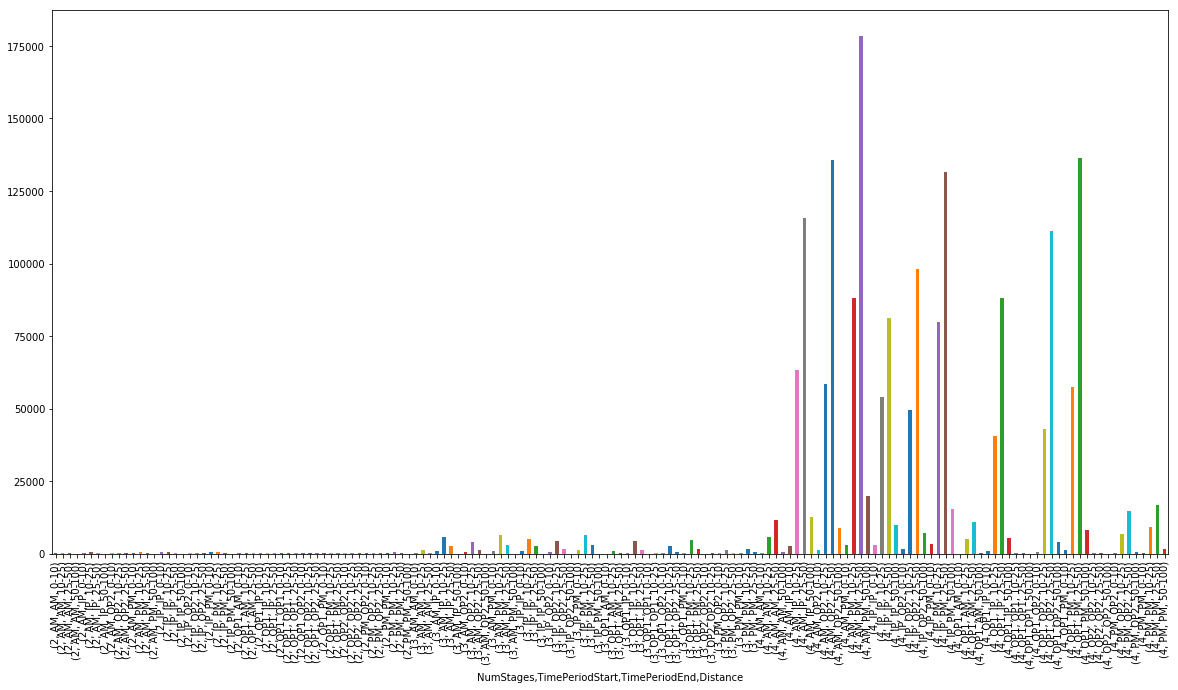

In [38]:
tcs_distr.plot('bar', figsize=(20,10))